## Week 8 - Performance Metrics
Confusion Matrix and Class-Level Evaluation¶
In this activity, you will train a dense neural network on the MNIST handwritten digit dataset, then evaluate it using tools that go beyond overall accuracy. You will generate a confusion matrix to see exactly which digits the model confuses, compute a classification report with per-class precision, recall, and F1-score, and visualize the results to identify patterns of error.

The goal is not simply to train a model, but to develop diagnostic evaluation skills that you will use throughout the remainder of this course and in your final project.

Run each section one at a time. Read the explanation before executing the code, and examine the output before moving on. Do not run all cells at once.

## Section 1: Setup and imports

In [1]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Reproducibility
tf.random.set_seed(42)
np.random.seed(42)

print("All libraries loaded successfully.")

All libraries loaded successfully.


## Section 2: Load and prepare the MNIST dataset
Load the MNIST dataset, normalize pixel values to [0, 1], and create a test set for evaluation. MNIST contains 70,000 grayscale images of handwritten digits (0 through 9), each 28x28 pixels. The 10 classes are roughly balanced, which means accuracy is a reasonable (though insufficient) starting metric. We will use the standard train/test split provided by Keras.

In [6]:
# Load MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

# Normalize and flatten
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Use a small subset
#x_train_small = x_train[:2000]
#y_train_small = y_train[:2000]
#x_test_small = x_test[:500]
#y_test_small = y_test[:500]

# Flatten images for simple models
#x_train_small_flat = x_train_small.reshape(2000, -1)
#x_test_small_flat = x_test_small.reshape(500, -1)

In [3]:
print(f"Training set: {x_train.shape[0]} images, shape {x_train.shape[1:]}")
print(f"Test set:     {x_test.shape[0]} images")
print(f"Classes:      {np.unique(y_test)}")
print(f"\nClass distribution in test set:")
for digit in range(10):
    count = np.sum(y_test == digit)
    print(f"  Digit {digit}: {count} samples ({count/len(y_test)*100:.1f}%)")

Training set: 60000 images, shape (28, 28)
Test set:     10000 images
Classes:      [0 1 2 3 4 5 6 7 8 9]

Class distribution in test set:
  Digit 0: 980 samples (9.8%)
  Digit 1: 1135 samples (11.3%)
  Digit 2: 1032 samples (10.3%)
  Digit 3: 1010 samples (10.1%)
  Digit 4: 982 samples (9.8%)
  Digit 5: 892 samples (8.9%)
  Digit 6: 958 samples (9.6%)
  Digit 7: 1028 samples (10.3%)
  Digit 8: 974 samples (9.7%)
  Digit 9: 1009 samples (10.1%)


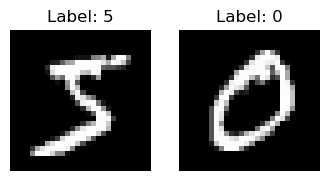

In [4]:
# Plot two sample digits from the training dataset
plt.figure(figsize=(4, 2))

plt.subplot(1, 2, 1)
plt.imshow(x_train_small[0], cmap='gray')
plt.title(f"Label: {y_train_small[0]}")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(x_train_small[1], cmap='gray')
plt.title(f"Label: {y_train_small[1]}")
plt.axis('off')

plt.show()

## Section 3: Build and train the model
We train a simple dense (fully connected) neural network on MNIST. The model has two hidden layers with ReLU activation and a softmax output layer for 10-class classification. This is not a state-of-the-art architecture for MNIST; it is intentionally simple so that the model makes enough errors for the evaluation to be interesting. A perfect model would produce a trivial confusion matrix with all counts on the diagonal.

In [5]:
# Build a simple dense network
model = keras.Sequential([
    layers.Flatten(input_shape=(28, 28)),       # flatten 28x28 image to 784-dim vector
    layers.Dense(128, activation="relu"),        # hidden layer 1
    layers.Dense(64, activation="relu"),         # hidden layer 2
    layers.Dense(10, activation="softmax")       # output: probability over 10 digits
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Train for 5 epochs (deliberately limited to produce some errors)
print("Training the model...")
history = model.fit(
    x_train, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# Report overall test accuracy
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"\nTest accuracy: {test_acc:.4f}")
print(f"Test loss:     {test_loss:.4f}")

C:\Users\phdst\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Training the model...
Epoch 1/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9021 - loss: 0.3479 - val_accuracy: 0.9598 - val_loss: 0.1388
Epoch 2/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9563 - loss: 0.1451 - val_accuracy: 0.9670 - val_loss: 0.1081
Epoch 3/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9705 - loss: 0.1011 - val_accuracy: 0.9718 - val_loss: 0.0961
Epoch 4/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9776 - loss: 0.0763 - val_accuracy: 0.9737 - val_loss: 0.0948
Epoch 5/5
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9827 - loss: 0.0600 - val_accuracy: 0.9740 - val_loss: 0.0926

Test accuracy: 0.9704
Test loss:     0.0924


## Section 4: Generate predictions
The model outputs a probability distribution over 10 classes for each input (via the softmax layer). We convert these probabilities to predicted class labels by taking the argmax. We also keep the raw probability outputs for confidence analysis later.

In [7]:
# Get predicted probabilities (softmax outputs)
y_pred_probs = model.predict(x_test, verbose=0)

# Convert to class labels
y_pred = np.argmax(y_pred_probs, axis=1)

print(f"Predictions generated for {len(y_pred)} test samples.")
print(f"Example: Test image 0 is digit {y_test[0]}, predicted as {y_pred[0]}")
print(f"         Probabilities: {np.round(y_pred_probs[0], 3)}")

Predictions generated for 10000 test samples.
Example: Test image 0 is digit 7, predicted as 7
         Probabilities: [0.    0.    0.    0.    0.    0.    0.    0.999 0.    0.   ]


## Section 5: Compute and visualize the confusion matrix
The confusion matrix is a 10x10 table where rows represent true labels and columns represent predicted labels. Diagonal entries are correct predictions; off-diagonal entries are misclassifications. We use a heatmap to make patterns visible at a glance.

Look carefully at the off-diagonal entries. Are the errors spread randomly, or are they concentrated between specific digit pairs? Which pairs show the most confusion?

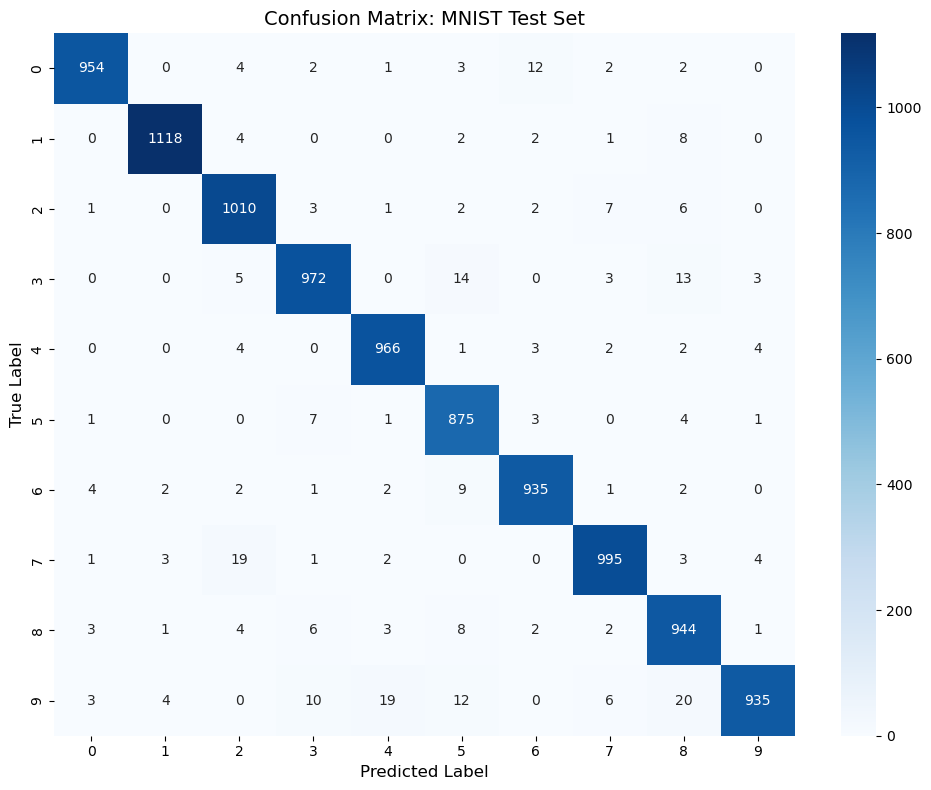


Correct predictions:   9704 / 10000
Incorrect predictions: 296 / 10000


In [8]:
# Compute confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Visualize as a heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,           # show counts in each cell
    fmt='d',              # integer format
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)
plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("Confusion Matrix: MNIST Test Set", fontsize=14)
plt.tight_layout()
plt.show()

# Print total correct and incorrect
correct = np.trace(cm)
total = np.sum(cm)
incorrect = total - correct
print(f"\nCorrect predictions:   {correct} / {total}")
print(f"Incorrect predictions: {incorrect} / {total}")

## Section 7: Generate the classification report
The classification report computes precision, recall, and F1-score for each digit class. This reveals which digits the model identifies reliably and which ones it struggles with. Pay attention to differences in precision versus recall for each class.


###  Precision for a digit = when the model predicts this digit, how often is it correct?
###  Recall for a digit = of all actual instances of this digit, how many did the model find?
###  F1-score = harmonic mean of precision and recall

In [9]:
# Full classification report
print("Classification Report:\n")
print(classification_report(y_test, y_pred, digits=4))

Classification Report:

              precision    recall  f1-score   support

           0     0.9866    0.9735    0.9800       980
           1     0.9911    0.9850    0.9881      1135
           2     0.9601    0.9787    0.9693      1032
           3     0.9701    0.9624    0.9662      1010
           4     0.9709    0.9837    0.9772       982
           5     0.9449    0.9809    0.9626       892
           6     0.9750    0.9760    0.9755       958
           7     0.9764    0.9679    0.9722      1028
           8     0.9402    0.9692    0.9545       974
           9     0.9863    0.9267    0.9555      1009

    accuracy                         0.9704     10000
   macro avg     0.9702    0.9704    0.9701     10000
weighted avg     0.9707    0.9704    0.9704     10000



## Section 8: Visualize per-class precision and recall
A bar chart makes it easier to compare precision and recall across all 10 classes at a glance. This visualization highlights which digits have balanced performance and which show a gap between precision and recall.

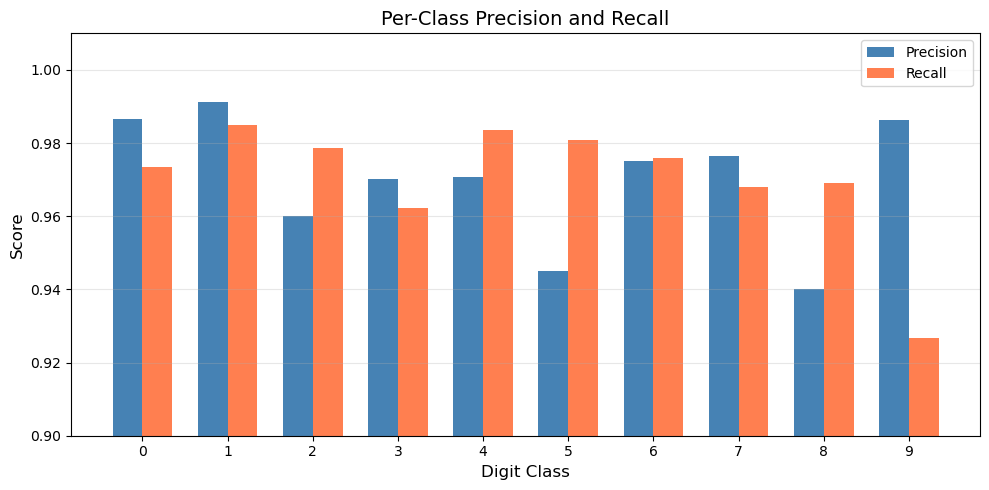


Digits with largest precision-recall gap:
  Digit 9: precision=0.9863, recall=0.9267, gap=0.0596
  Digit 5: precision=0.9449, recall=0.9809, gap=0.0360
  Digit 8: precision=0.9402, recall=0.9692, gap=0.0290


In [10]:
from sklearn.metrics import precision_score, recall_score

# Compute per-class precision and recall
per_class_precision = precision_score(y_test, y_pred, average=None)
per_class_recall = recall_score(y_test, y_pred, average=None)

# Plot side-by-side comparison
x = np.arange(10)
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, per_class_precision, width, label='Precision', color='steelblue')
bars2 = ax.bar(x + width/2, per_class_recall, width, label='Recall', color='coral')

ax.set_xlabel('Digit Class', fontsize=12)
ax.set_ylabel('Score', fontsize=12)
ax.set_title('Per-Class Precision and Recall', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(range(10))
ax.set_ylim(0.90, 1.01)    # zoom in to make differences visible
ax.legend()
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

# Print the two digits with the largest difference between precision and recall
diff = np.abs(per_class_precision - per_class_recall)
top_diff = np.argsort(diff)[::-1][:3]
print("\nDigits with largest precision-recall gap:")
for d in top_diff:
    print(f"  Digit {d}: precision={per_class_precision[d]:.4f}, recall={per_class_recall[d]:.4f}, gap={diff[d]:.4f}")

## Section 9: Visualize misclassified examples


Total misclassified: 296 out of 10000



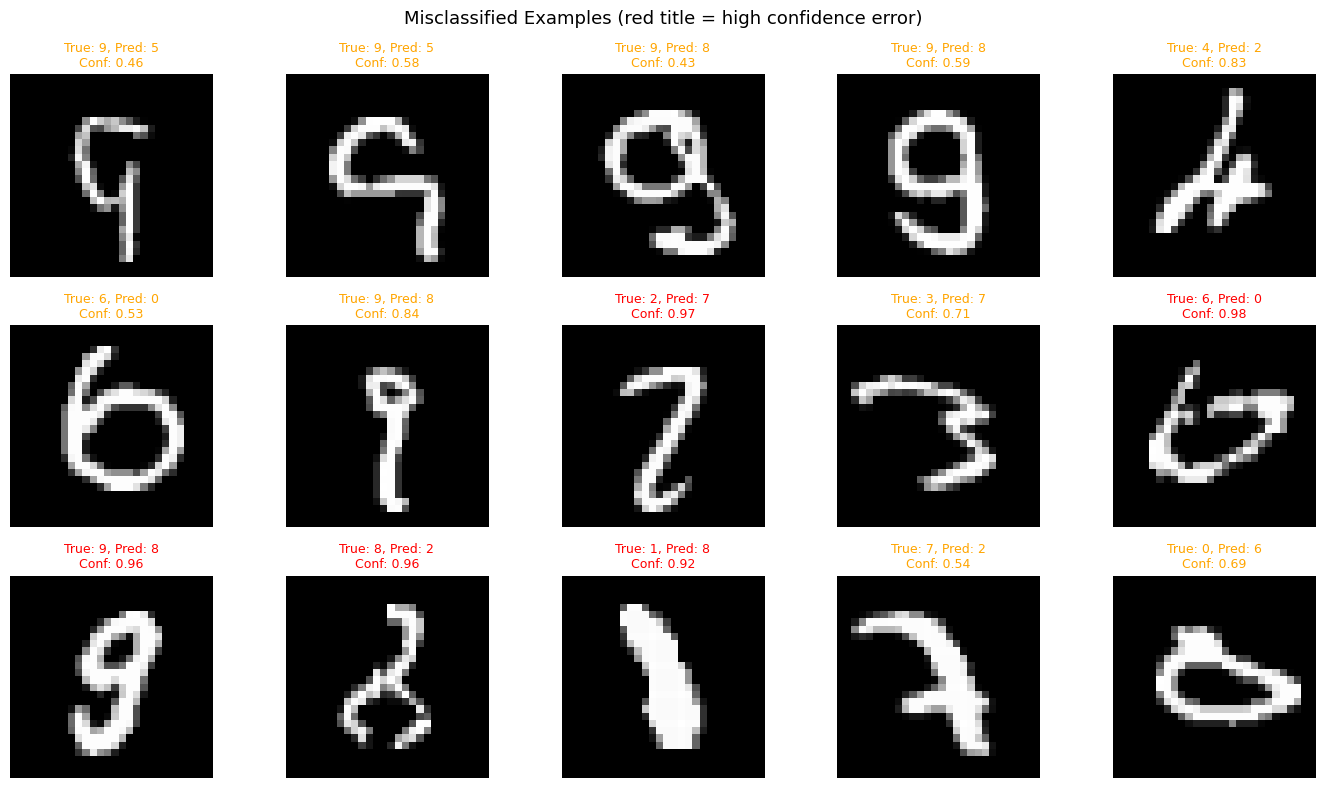

In [12]:
# Find indices of misclassified examples
incorrect_idx = np.where(y_pred != y_test)[0]
print(f"Total misclassified: {len(incorrect_idx)} out of {len(y_test)}\n")

# Display first 15 misclassified examples
fig, axes = plt.subplots(3, 5, figsize=(14, 8))
for i, ax in enumerate(axes.flat):
    if i < len(incorrect_idx):
        idx = incorrect_idx[i]
        ax.imshow(x_test[idx].reshape(28, 28), cmap='gray')
        confidence = np.max(y_pred_probs[idx])
        ax.set_title(
            f"True: {y_test[idx]}, Pred: {y_pred[idx]}\n"
            f"Conf: {confidence:.2f}",
            fontsize=9,
            color='red' if confidence > 0.9 else 'orange'
        )
    ax.axis('off')

plt.suptitle("Misclassified Examples (red title = high confidence error)", fontsize=13)
plt.tight_layout()
plt.show()

## ROC implementation in Keras
The code below demonstrates how to generate ROC curves and compute AUC for a multi-class classifier using scikit-learn's roc_curve and auc functions. Because these functions operate on binary problems, we first binarize the true labels using the one-versus-rest approach discussed above. The model's softmax outputs already provide per-class probabilities, so no additional transformation is needed on the prediction side.

The result is a single plot with one ROC curve per class, each annotated with its AUC value.

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step 


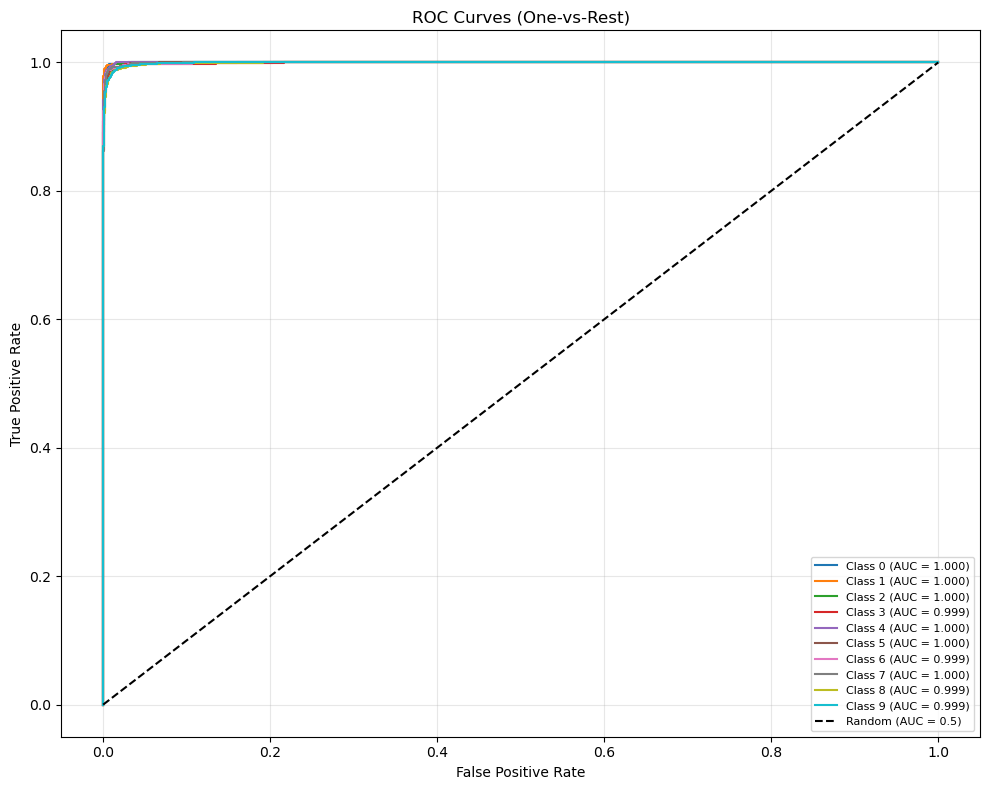

In [13]:
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

# Binarize labels for multi-class ROC (one-vs-rest)
y_test_bin = label_binarize(y_test, classes=range(10))

# Get predicted probabilities
y_pred_probs = model.predict(x_test)

# Plot ROC curve for each class
plt.figure(figsize=(10, 8))
for i in range(10):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_pred_probs[:, i])
    roc_auc = auc(fpr, tpr)
    plt.plot(fpr, tpr, label=f'Class {i} (AUC = {roc_auc:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves (One-vs-Rest)')
plt.legend(loc='lower right', fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()